# Early classification pada light curve dengan fitur raw

Notebook ini menguji kemampuan model memprediksi kelas dari prefix kronologis light curve menggunakan enam fitur raw. Model tidak dilatih ulang: checkpoint seed 42 digunakan untuk menguji 6, 10, 15, 20, 30, dan seluruh detection. Pemotongan dilakukan berdasarkan jumlah detection riil kronologis dan detection setelah prefix dikeluarkan dari mask.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from alerce_classifier.models import HybridCNNGRU, CNNClassifier, GRUClassifier
from alerce_classifier.training.loop import (
    evaluate_detection_prefixes, load_split, make_loader, evaluate,
)

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / 'pyproject.toml').is_file() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent
if not (REPO_ROOT / 'pyproject.toml').is_file():
    raise FileNotFoundError('Repository root tidak ditemukan')
DATA_DIR = REPO_ROOT / 'data' / 'alerce_ztf_lc_sanchezsaez_full' / 'data' / 'full'
RAW_OUTPUT_DIR = DATA_DIR / 'preprocessing' / 'notebook_output'
ARTIFACT_DIR = REPO_ROOT / 'artifacts'
OUTPUT_DIR = ARTIFACT_DIR / 'benchmark'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FEATURE_CONFIG = json.loads((ARTIFACT_DIR / 'feature_config.json').read_text(encoding='utf-8'))
FEATURE_COUNT = len(FEATURE_CONFIG['features'])
EXPECTED_FEATURES = ['time_rel', 'delta_time', 'magnitude', 'magnitude_error', 'filter_g', 'filter_r']
if FEATURE_CONFIG['features'] != EXPECTED_FEATURES:
    raise ValueError(
        'Checkpoint seed 42 adalah model raw 6 fitur. '
        f"feature_config.json berisi {len(FEATURE_CONFIG['features'])} fitur."
    )
SEED = 42
BATCH_SIZE = 64
DETECTION_COUNTS = [6, 10, 15, 20, 30]
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
print('Feature count:', FEATURE_COUNT)
print('Detection counts:', DETECTION_COUNTS)


Device: cuda
Feature count: 6
Detection counts: [6, 10, 15, 20, 30]


## 1. Validasi artifact dan memuat test sequence

In [2]:
required = [
    RAW_OUTPUT_DIR / 'test_padded.npz',
    ARTIFACT_DIR / 'hybrid' / 'hybrid_cnn_gru_seed42_best.pt',
    ARTIFACT_DIR / 'cnn' / 'cnn_seed42_best.pt',
    ARTIFACT_DIR / 'gru' / 'gru_seed42_best.pt',
]
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError(f'Artifact early classification tidak lengkap: {missing}')
test_tensors = load_split(RAW_OUTPUT_DIR / 'test_padded.npz')
test_x, test_mask, test_y = test_tensors
print('Test tensor:', tuple(test_x.shape))
print('Test labels:', torch.bincount(test_y, minlength=3).tolist())
print('Mean real sequence length:', float(test_mask.sum(dim=1).float().mean()))


Test tensor: (18525, 1088, 6)
Test labels: [13060, 5207, 258]
Mean real sequence length: 410.9811706542969


## 2. Memuat checkpoint terbaik

Checkpoint dipilih pada eksperimen training berdasarkan validation macro-F1. Test set hanya digunakan untuk evaluasi prefix pada notebook ini.

In [3]:
model_factories = {
    'hybrid_cnn_gru': HybridCNNGRU,
    'cnn': CNNClassifier,
    'gru': GRUClassifier,
}
checkpoint_paths = {
    'hybrid_cnn_gru': ARTIFACT_DIR / 'hybrid' / 'hybrid_cnn_gru_seed42_best.pt',
    'cnn': ARTIFACT_DIR / 'cnn' / 'cnn_seed42_best.pt',
    'gru': ARTIFACT_DIR / 'gru' / 'gru_seed42_best.pt',
}
missing_checkpoints = [str(path) for path in checkpoint_paths.values() if not path.is_file()]
if missing_checkpoints:
    raise FileNotFoundError(f'Checkpoint tidak lengkap: {missing_checkpoints}')
models = {}
checkpoint_summary = {}
for model_name, factory in model_factories.items():
    model = factory(feature_count=FEATURE_COUNT).to(DEVICE)
    checkpoint_path = checkpoint_paths[model_name]
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
    models[model_name] = model
    checkpoint_summary[model_name] = {
        'best_epoch': checkpoint['best_epoch'],
        'best_validation_macro_f1': checkpoint['best_validation_macro_f1'],
    }
print(json.dumps(checkpoint_summary, indent=2))


{
  "hybrid_cnn_gru": {
    "best_epoch": 27,
    "best_validation_macro_f1": 0.969654492719274
  },
  "cnn": {
    "best_epoch": 21,
    "best_validation_macro_f1": 0.952757844210077
  },
  "gru": {
    "best_epoch": 24,
    "best_validation_macro_f1": 0.9687219735305644
  }
}


## 3. Evaluasi prefix kronologis

Untuk setiap OID dan fraction, hanya detection pertama sampai batas prefix yang dipertahankan. Nilai setelah batas tersebut menjadi nol dan mask-nya menjadi 0. Tidak ada retraining atau penggunaan detection masa depan.

In [4]:
prefix_results = {}
for model_name, model in models.items():
    print(f'Evaluating {model_name}', flush=True)
    prefix_results[model_name] = evaluate_detection_prefixes(
        model, test_x, test_mask, test_y,
        [*DETECTION_COUNTS, None], DEVICE
    )
    for detection_count, metrics in prefix_results[model_name].items():
        print(
            f'  {detection_count}: accuracy={metrics["accuracy"]:.4f}, '
            f'balanced_accuracy={metrics["balanced_accuracy"]:.4f}, '
            f'macro_precision={metrics["macro_precision"]:.4f}, '
            f'macro_recall={metrics["macro_recall"]:.4f}, '
            f'macro_f1={metrics["macro_f1"]:.4f}'
        )
(OUTPUT_DIR / 'early_classification_metrics.json').write_text(
    json.dumps(prefix_results, indent=2), encoding='utf-8'
)


Evaluating hybrid_cnn_gru
  6: accuracy=0.6090, balanced_accuracy=0.7083, macro_precision=0.5267, macro_recall=0.7083, macro_f1=0.4812
  10: accuracy=0.6491, balanced_accuracy=0.7921, macro_precision=0.5423, macro_recall=0.7921, macro_f1=0.5140
  15: accuracy=0.6774, balanced_accuracy=0.8156, macro_precision=0.5420, macro_recall=0.8156, macro_f1=0.5255
  20: accuracy=0.7123, balanced_accuracy=0.8380, macro_precision=0.5471, macro_recall=0.8380, macro_f1=0.5411
  30: accuracy=0.7660, balanced_accuracy=0.8656, macro_precision=0.5566, macro_recall=0.8656, macro_f1=0.5651
  all: accuracy=0.9740, balanced_accuracy=0.9681, macro_precision=0.9686, macro_recall=0.9681, macro_f1=0.9684
Evaluating cnn
  6: accuracy=0.5408, balanced_accuracy=0.7106, macro_precision=0.5181, macro_recall=0.7106, macro_f1=0.4430
  10: accuracy=0.6334, balanced_accuracy=0.7825, macro_precision=0.5433, macro_recall=0.7825, macro_f1=0.5052
  15: accuracy=0.6886, balanced_accuracy=0.8130, macro_precision=0.5623, macro_r

29019

## 4. Ringkasan perbandingan model

In [5]:
rows = []
for model_name, results in prefix_results.items():
    for detection_count, metrics in results.items():
        rows.append({
            'model': model_name,
            'detection_count': detection_count,
            'accuracy': metrics['accuracy'],
            'balanced_accuracy': metrics['balanced_accuracy'],
            'macro_precision': metrics['macro_precision'],
            'macro_recall': metrics['macro_recall'],
            'macro_f1': metrics['macro_f1'],
        })
summary = pd.DataFrame(rows)
summary['sort_count'] = summary['detection_count'].replace({'all': 999999}).astype(int)
summary = summary.sort_values(['sort_count', 'macro_f1'], ascending=[True, False])
display(summary)
summary.to_csv(OUTPUT_DIR / 'early_classification_summary.csv', index=False)


,model,detection_count,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,sort_count
0,hybrid_cnn_gru,6,0.609015,0.708264,0.526750,0.708264,0.481242,6
6,cnn,6,0.540783,0.710633,0.518106,0.710633,0.443034,6
12,gru,6,0.495978,0.626767,0.491626,0.626767,0.396927,6
1,hybrid_cnn_gru,10,0.649088,0.792127,0.542260,0.792127,0.514010,10
7,cnn,10,0.633386,0.782508,0.543274,0.782508,0.505162,10
13,gru,10,0.558774,0.741271,0.525087,0.741271,0.456396,10
8,cnn,15,0.688586,0.812974,0.562344,0.812974,0.536210,15
2,hybrid_cnn_gru,15,0.677381,0.815591,0.542040,0.815591,0.525499,15
14,gru,15,0.639390,0.793118,0.539779,0.793118,0.502699,15
9,cnn,20,0.727619,0.831854,0.574070,0.831854,0.554203,20


## 5. Grafik early classification

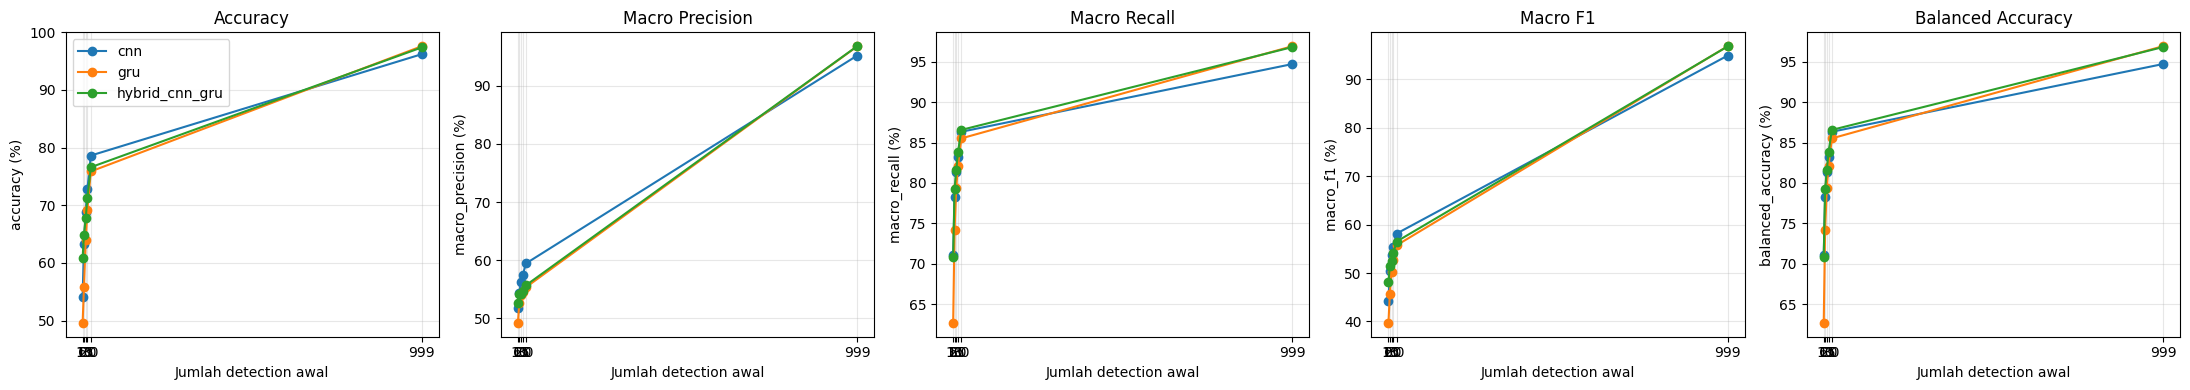

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
metrics_to_plot = ('accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'balanced_accuracy')
for metric, axis in zip(metrics_to_plot, axes):
    for model_name, group in summary.groupby('model'):
        group = group.sort_values('sort_count')
        axis.plot(group['sort_count'].replace({999999: 999}), group[metric] * 100, marker='o', label=model_name)
    axis.set_xlabel('Jumlah detection awal')
    axis.set_ylabel(f'{metric} (%)')
    axis.set_title(metric.replace('_', ' ').title())
    axis.set_xticks([6, 10, 15, 20, 30, 999])
    axis.grid(alpha=.3)
axes[0].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'early_classification_curves.png', dpi=150)
plt.show()


## 6. Confusion matrix pada prefix awal

Confusion matrix berikut membantu melihat apakah keunggulan awal model berasal dari pengenalan kelas tertentu atau dari dominasi kelas Periodic.

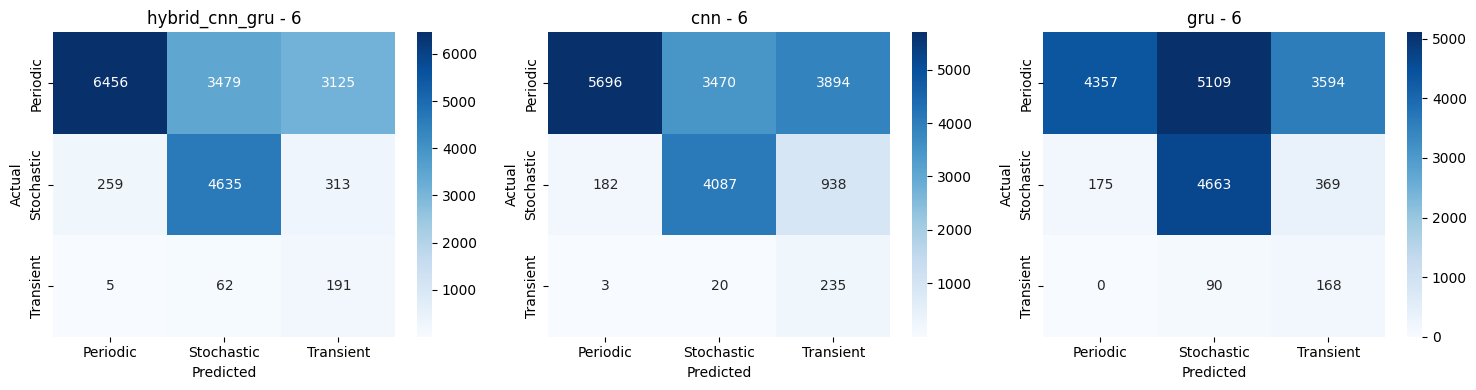

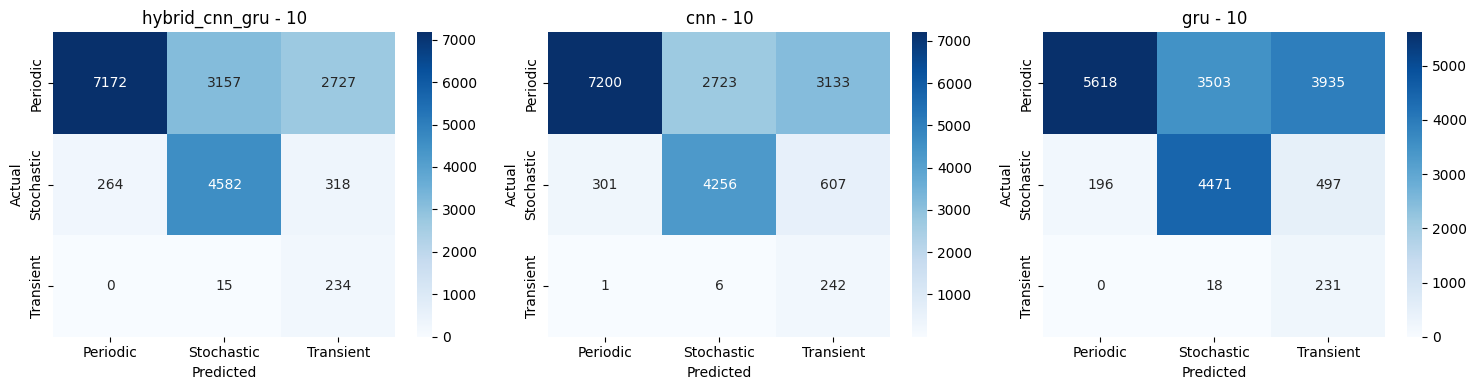

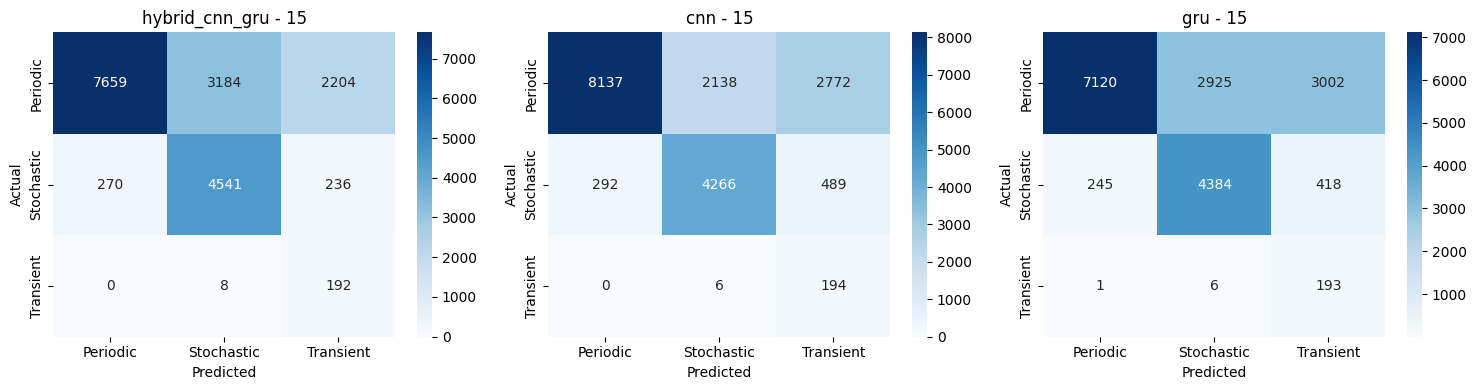

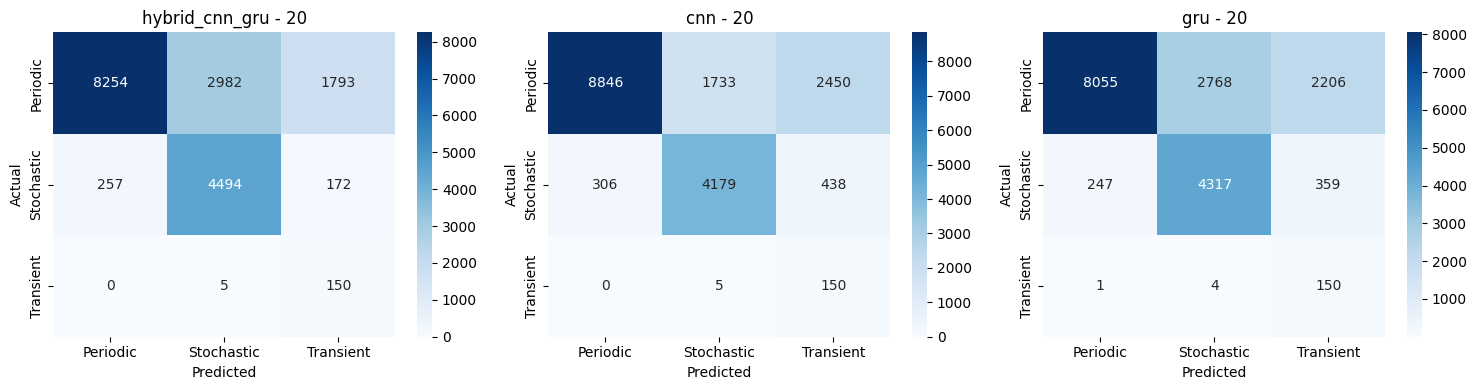

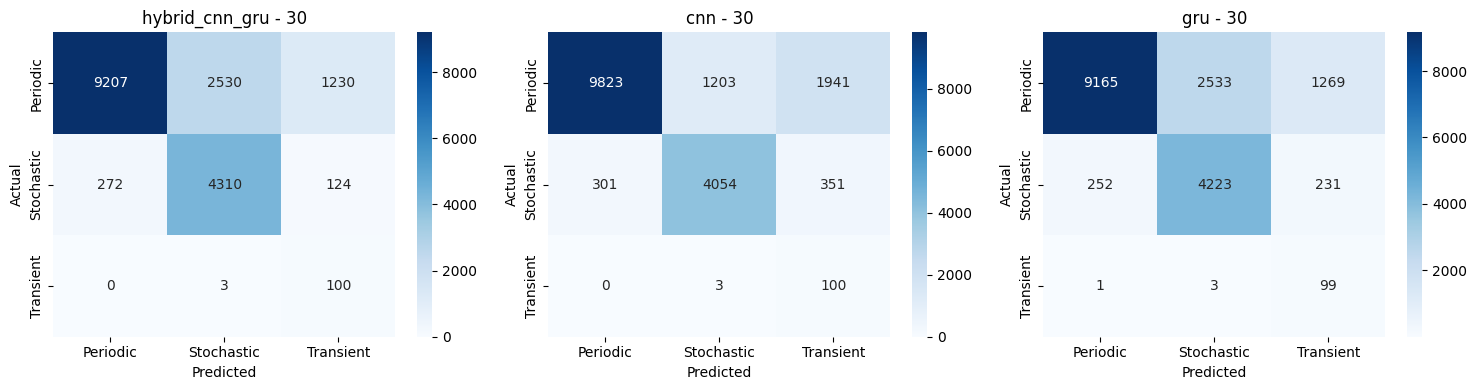

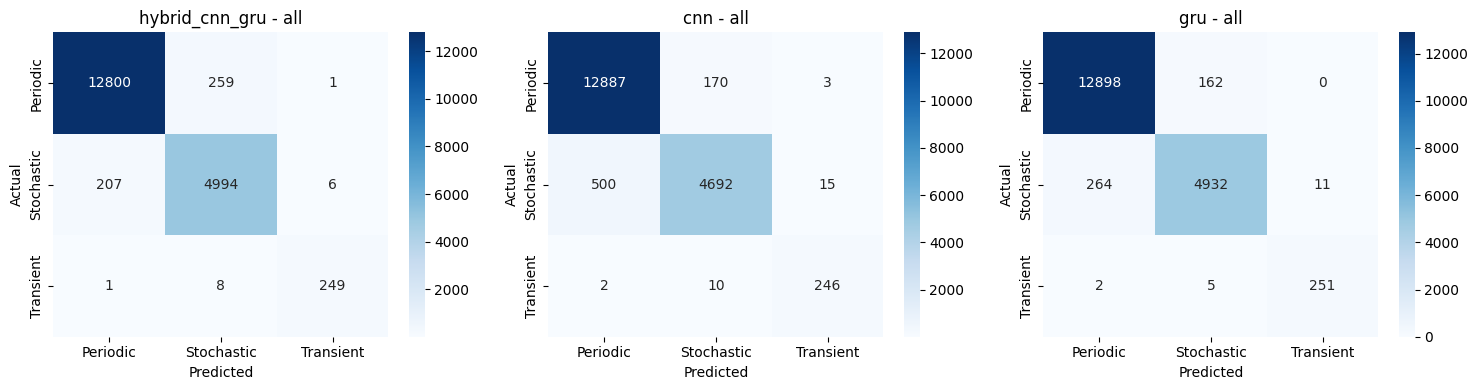

In [7]:
class_names = ['Periodic', 'Stochastic', 'Transient']
for detection_count in [*DETECTION_COUNTS, 'all']:
    key = str(detection_count)
    fig, axes = plt.subplots(1, len(models), figsize=(15, 4))
    for axis, (model_name, results) in zip(axes, prefix_results.items()):
        sns.heatmap(
        results[str(detection_count)]['confusion_matrix'], annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axis,
        )
        axis.set_title(f'{model_name} - {detection_count}')
        axis.set_xlabel('Predicted')
        axis.set_ylabel('Actual')
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"confusion_matrix_detection_{detection_count}.png", dpi=150)
    plt.show()


## Interpretasi yang diuji

Eksperimen menguji robustness model terhadap prefix dengan jumlah detection absolut 6, 10, 15, 20, dan 30, serta seluruh sequence. Model tidak dilatih ulang. Hasil ditafsirkan menggunakan Macro-F1, balanced accuracy, coverage, dan confusion matrix.

## Review artifact hasil early classification dan efisiensi

Cell berikut membaca `metrics.json`, `summary.csv`, dan `benchmark.json` dari setiap model. Threshold hanya dibaca dari hasil yang sudah dievaluasi: 6, 10, 15, 20, 30, dan all.

In [8]:
from pathlib import Path
import json
import pandas as pd

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / 'pyproject.toml').is_file() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent
ARTIFACT_DIR = REPO_ROOT / 'artifacts'
MODEL_NAMES = ('cnn', 'gru', 'hybrid')

metric_rows = []
coverage_rows = []
efficiency_rows = []
transient_rows = []

for model_name in MODEL_NAMES:
    model_dir = ARTIFACT_DIR / model_name / 'early_classification'
    metrics_path = model_dir / 'metrics.json'
    benchmark_path = model_dir / 'benchmark.json'
    if not metrics_path.is_file() or not benchmark_path.is_file():
        raise FileNotFoundError(f'Artifact early classification belum lengkap: {model_name}')

    metrics = json.loads(metrics_path.read_text(encoding='utf-8'))
    benchmark = json.loads(benchmark_path.read_text(encoding='utf-8'))
    for count_key, values in metrics.items():
        if count_key == 'protocol':
            continue
        label = 'all' if count_key == 'all' else str(count_key)
        metric_rows.append({
            'model': model_name, 'detection_count': label,
            'accuracy': values['accuracy'],
            'macro_precision': values['macro_precision'],
            'macro_recall': values['macro_recall'],
            'macro_f1': values['macro_f1'],
            'balanced_accuracy': values['balanced_accuracy'],
        })
        coverage_rows.append({
            'model': model_name, 'detection_count': label,
            'valid_object_count': values['valid_object_count'],
            'coverage': values['coverage'],
        })
        transient = values['classification_report']['Transient']
        transient_rows.append({
            'model': model_name, 'detection_count': label,
            'transient_precision': transient['precision'],
            'transient_recall': transient['recall'],
            'transient_f1': transient['f1-score'],
        })

    for count_key, values in benchmark.items():
        efficiency_rows.append({
            'model': model_name, 'detection_count': 'all' if count_key == 'all' else str(count_key),
            'valid_object_count': values['valid_object_count'],
            'inference_seconds': values['inference_seconds'],
            'inference_seconds_per_object': values['inference_seconds_per_object'],
            'peak_gpu_memory_mib': values['peak_memory_bytes'] / (1024 ** 2),
        })

metric_table = pd.DataFrame(metric_rows)
coverage_table = pd.DataFrame(coverage_rows)
efficiency_table = pd.DataFrame(efficiency_rows)
transient_table = pd.DataFrame(transient_rows)
sort_order = {'6':6, '10':10, '15':15, '20':20, '30':30, 'all':999999}
for table in (metric_table, coverage_table, efficiency_table, transient_table):
    table['sort_count'] = table['detection_count'].map(sort_order)
    table.sort_values(['sort_count', 'model'], inplace=True)

display(metric_table.drop(columns='sort_count').style.format({
    'accuracy': '{:.2%}', 'macro_precision': '{:.2%}', 'macro_recall': '{:.2%}',
    'macro_f1': '{:.2%}', 'balanced_accuracy': '{:.2%}',
}))
display(coverage_table.drop(columns='sort_count').style.format({'coverage': '{:.2%}'}))
display(transient_table.drop(columns='sort_count').style.format({
    'transient_precision': '{:.2%}', 'transient_recall': '{:.2%}', 'transient_f1': '{:.2%}',
}))
display(efficiency_table.drop(columns='sort_count').style.format({
    'inference_seconds': '{:.4f}', 'inference_seconds_per_object': '{:.6f}',
    'peak_gpu_memory_mib': '{:.2f}',
}))

prefix_only = metric_table[metric_table['detection_count'] != 'all'].copy()
winner = prefix_only.loc[prefix_only.groupby('sort_count')['macro_f1'].idxmax(), ['detection_count','model','macro_f1']]
print('Pemenang Macro-F1 pada masing-masing prefix:')
display(winner.style.format({'macro_f1': '{:.2%}'}))

,model,detection_count,accuracy,macro_precision,macro_recall,macro_f1,balanced_accuracy
0,cnn,6,54.08%,51.81%,71.06%,44.30%,71.06%
6,gru,6,49.60%,49.16%,62.68%,39.69%,62.68%
12,hybrid,6,60.90%,52.67%,70.83%,48.12%,70.83%
1,cnn,10,63.34%,54.33%,78.25%,50.52%,78.25%
7,gru,10,55.88%,52.51%,74.13%,45.64%,74.13%
13,hybrid,10,64.91%,54.23%,79.21%,51.40%,79.21%
2,cnn,15,68.86%,56.23%,81.30%,53.62%,81.30%
8,gru,15,63.94%,53.98%,79.31%,50.27%,79.31%
14,hybrid,15,67.74%,54.20%,81.56%,52.55%,81.56%
3,cnn,20,72.76%,57.41%,83.19%,55.42%,83.19%


,model,detection_count,valid_object_count,coverage
0,cnn,6,18525,100.00%
6,gru,6,18525,100.00%
12,hybrid,6,18525,100.00%
1,cnn,10,18469,99.70%
7,gru,10,18469,99.70%
13,hybrid,10,18469,99.70%
2,cnn,15,18294,98.75%
8,gru,15,18294,98.75%
14,hybrid,15,18294,98.75%
3,cnn,20,18107,97.74%


,model,detection_count,transient_precision,transient_recall,transient_f1
0,cnn,6,4.64%,91.09%,8.83%
6,gru,6,4.07%,65.12%,7.66%
12,hybrid,6,5.26%,74.03%,9.83%
1,cnn,10,6.08%,97.19%,11.44%
7,gru,10,4.95%,92.77%,9.41%
13,hybrid,10,7.14%,93.98%,13.27%
2,cnn,15,5.62%,97.00%,10.62%
8,gru,15,5.34%,96.50%,10.12%
14,hybrid,15,7.29%,96.00%,13.56%
3,cnn,20,4.94%,96.77%,9.40%


,model,detection_count,valid_object_count,inference_seconds,inference_seconds_per_object,peak_gpu_memory_mib
0,cnn,6,18525,0.2494,0.000013,45.24
6,gru,6,18525,0.3536,0.000019,19.85
12,hybrid,6,18525,0.3930,0.000021,45.24
1,cnn,10,18469,0.2422,0.000013,45.24
7,gru,10,18469,0.3732,0.000020,19.99
13,hybrid,10,18469,0.3979,0.000022,45.24
2,cnn,15,18294,0.2530,0.000014,45.24
8,gru,15,18294,0.3938,0.000022,20.31
14,hybrid,15,18294,0.4332,0.000024,45.24
3,cnn,20,18107,0.2382,0.000013,45.24


Pemenang Macro-F1 pada masing-masing prefix:


,detection_count,model,macro_f1
12,6,hybrid,48.12%
13,10,hybrid,51.40%
2,15,cnn,53.62%
3,20,cnn,55.42%
4,30,cnn,58.15%
